# Workshop 2 — Machine Learning (Unidad 2)
## Problema de Clasificación: recurrencia de cáncer diferenciado de tiroides

**Dataset:** Thyroid Disease Data — https://www.kaggle.com/datasets/jainaru/thyroid-disease-data

Los puntos 14, 15, 18 y 25 del enunciado pertenecen al problema de regresión y se desarrollan en el notebook de regresión del equipo. En este notebook se resuelven los puntos que aplican al problema de clasificación: 1 a 13, 16, 17, 19 a 24, 26, 27 y 28.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

plt.rcParams['figure.figsize'] = (7, 5)
random_state = 42

---
# Fase 1 — EDA, limpieza y preprocesamiento

## 1. Descripción del problema y variable objetivo

El dataset proviene del repositorio UCI (*Differentiated Thyroid Cancer Recurrence*) y recoge 13 características clínico-patológicas de pacientes tratados por cáncer diferenciado de tiroides. Los datos se recolectaron durante 15 años y cada paciente tuvo un seguimiento de al menos 10 años.

**Problema de salud:** el cáncer diferenciado de tiroides (papilar, folicular, de células de Hürthle) tiene muy buen pronóstico, pero una fracción de los pacientes presenta **recurrencia** después del tratamiento inicial (cirugía y, en muchos casos, yodo radiactivo). Identificar de forma temprana a los pacientes con alto riesgo de recurrencia permite ajustar la intensidad del seguimiento: controles más frecuentes y estudios de imagen adicionales para los pacientes de riesgo, y un seguimiento más liviano para los de bajo riesgo, evitando costos y ansiedad innecesarios.

**Variable objetivo (target):** `Recurred`, con dos categorías (`Yes` / `No`), que indica si el paciente presentó recurrencia de la enfermedad durante el seguimiento. Es una variable **categórica binaria**, por lo que el problema es de **clasificación binaria** y no de regresión. La clase positiva de interés es `Yes` (hubo recurrencia).

## 2. Carga del dataset y diccionario de datos

In [2]:
df = pd.read_csv("Thyroid_Diff.csv")
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [3]:
df.tail()

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
378,72,M,Yes,Yes,Yes,Euthyroid,Single nodular goiter-right,Right,Papillary,Uni-Focal,High,T4b,N1b,M1,IVB,Biochemical Incomplete,Yes
379,81,M,Yes,No,Yes,Euthyroid,Multinodular goiter,Extensive,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
380,72,M,Yes,Yes,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
381,61,M,Yes,Yes,Yes,Clinical Hyperthyroidism,Multinodular goiter,Extensive,Hurthel cell,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes
382,67,M,Yes,No,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes


In [4]:
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (383, 17)
<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 n

### Diccionario de datos

| Columna | Tipo esperado | Significado |
|---|---|---|
| `Age` | Numérica discreta (años) | Edad del paciente al momento del diagnóstico o tratamiento |
| `Gender` | Categórica nominal (F/M) | Sexo del paciente |
| `Smoking` | Categórica binaria (Yes/No) | Si el paciente es fumador actualmente |
| `Hx Smoking` | Categórica binaria (Yes/No) | Antecedente de tabaquismo (si alguna vez fumó) |
| `Hx Radiothreapy` | Categórica binaria (Yes/No) | Antecedente de radioterapia por cualquier causa (el nombre viene con el error de digitación del archivo original) |
| `Thyroid Function` | Categórica nominal (5 niveles) | Estado funcional de la tiroides (eutiroidismo, hiper/hipotiroidismo clínico o subclínico) |
| `Physical Examination` | Categórica nominal (5 niveles) | Hallazgos del examen físico de la glándula (bocio uninodular, multinodular, difuso, normal) |
| `Adenopathy` | Categórica nominal (6 niveles) | Presencia y ubicación de ganglios linfáticos aumentados en el cuello |
| `Pathology` | Categórica nominal (4 niveles) | Tipo histológico del tumor según la biopsia |
| `Focality` | Categórica binaria | Si el tumor es unifocal o multifocal |
| `Risk` | Categórica **ordinal** (Low < Intermediate < High) | Categoría de riesgo asignada por el equipo clínico |
| `T` | Categórica **ordinal** (T1a < T1b < T2 < T3a < T3b < T4a < T4b) | Clasificación del tumor por tamaño e invasión local (TNM) |
| `N` | Categórica **ordinal** (N0 < N1a < N1b) | Compromiso ganglionar (TNM) |
| `M` | Categórica binaria (M0/M1) | Presencia de metástasis a distancia (TNM) |
| `Stage` | Categórica **ordinal** (I < II < III < IVA < IVB) | Estadio final de la enfermedad |
| `Response` | Categórica nominal (4 niveles) | Respuesta al tratamiento inicial (excelente, indeterminada, incompleta bioquímica, incompleta estructural) |
| `Recurred` | Categórica binaria (Yes/No) | **Variable objetivo**: si hubo recurrencia durante el seguimiento |

El `.info()` confirma lo esperado: 16 columnas de tipo texto (categóricas) y una sola columna numérica (`Age`). Esta es la característica más importante del dataset para todo lo que sigue: **es un dataset esencialmente categórico**, lo que condiciona las decisiones de encoding, de escalamiento y hasta la elección de gráficas.

## 3. Estadísticos descriptivos

In [5]:
df.describe()

,Age
count,383.000000
mean,40.866841
std,15.134494
min,15.000000
25%,29.000000
50%,37.000000
75%,51.000000
max,82.000000


In [6]:
df.describe(exclude=np.number)

,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
count,383,383,383,383,383,383,383,383,383,383,383,383,383,383,383,383
unique,2,2,2,2,5,5,6,4,2,3,7,3,2,5,4,2
top,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
freq,312,334,355,376,332,140,277,287,247,249,151,268,365,333,208,275


**Interpretación de tres estadísticos (columna `Age`, la única numérica):**

1. **Media ≈ 40.9 años y mediana = 37 años.** La media es mayor que la mediana, lo que indica una distribución con sesgo a la derecha: la mayoría de los pacientes son relativamente jóvenes y unos pocos casos de edad avanzada estiran el promedio. Esto es coherente con la epidemiología del cáncer de tiroides, que se diagnostica con frecuencia en adultos jóvenes, sobre todo mujeres.

2. **Desviación estándar ≈ 15.1 años sobre una media de 40.9.** La dispersión es alta en términos relativos (coeficiente de variación cercano al 37%), es decir, la cohorte no es homogénea en edad. Como la edad es un factor pronóstico reconocido en el estadiaje del cáncer de tiroides, esta variabilidad es información útil y no ruido.

3. **Rango de 15 a 82 años (mín–máx).** No hay edades imposibles (negativas, cero o mayores a 120), así que no hay errores evidentes de captura en esta columna. El percentil 75 está en 51 años, o sea que tres de cada cuatro pacientes tienen 51 años o menos.

Del `describe` de las columnas categóricas vale la pena resaltar que la columna objetivo `Recurred` tiene como valor más frecuente `No` con 275 de 383 registros: hay **desbalance de clases** (aproximadamente 72% / 28%). Esto se tendrá en cuenta al estratificar las particiones y al elegir las métricas de evaluación.

## 4. Valores nulos y estrategia de imputación

In [7]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2)
})
nulos

,nulos,porcentaje
Age,0,0.0
Gender,0,0.0
Smoking,0,0.0
Hx Smoking,0,0.0
Hx Radiothreapy,0,0.0
Thyroid Function,0,0.0
Physical Examination,0,0.0
Adenopathy,0,0.0
Pathology,0,0.0
Focality,0,0.0


**Justificación de la estrategia:**

El dataset **no tiene valores nulos** en ninguna de las 17 columnas (0.00% en todas). Por lo tanto no hay que imputar ni eliminar filas ni columnas por este motivo, y no se pierde ni un solo registro, lo cual es importante en un dataset pequeño (383 filas).

Aun así, en la Fase 2 se incluyen imputadores dentro del `ColumnTransformer`. La razón no es que existan nulos hoy, sino que el pipeline es el objeto que quedaría en producción: si mañana llega un paciente nuevo con la casilla "Adenopathy" sin diligenciar, el pipeline debe poder transformarlo sin romperse. La estrategia definida es:

- **`Age` (numérica):** imputación por la **mediana**. Como se vio en el punto 3, la distribución tiene sesgo a la derecha, y la mediana es más resistente a ese sesgo que la media.
- **Variables categóricas:** imputación por la **moda** (`most_frequent`). Para una variable categórica no existe "el promedio"; la única imputación con sentido a partir de la propia columna es la categoría más frecuente.

Si el dataset hubiera tenido nulos, el criterio habría sido: menos del 5% en una columna, imputar; más del 40-50% en una columna, evaluar eliminar la columna completa porque la imputación estaría inventando la mayor parte de la información.

## 5. Registros duplicados

In [8]:
duplicados = df.duplicated().sum()
print("Filas duplicadas encontradas:", duplicados)

filas_antes = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Filas antes:", filas_antes)
print("Filas después:", df.shape[0])
print("Filas eliminadas:", filas_antes - df.shape[0])

Filas duplicadas encontradas: 19
Filas antes: 383
Filas después: 364
Filas eliminadas: 19


**Justificación:** se encontraron **19 filas exactamente duplicadas** (5% del dataset) y se eliminaron, quedando 364 registros.

La decisión merece una aclaración porque no es trivial: el dataset no tiene un identificador de paciente, y con solo 17 variables de baja cardinalidad es perfectamente posible que dos pacientes distintos compartan exactamente el mismo perfil clínico (por ejemplo, dos mujeres de 30 años, no fumadoras, eutiroideas, T1a N0 M0, riesgo bajo, respuesta excelente, sin recurrencia). Es decir, algunas de estas filas podrían ser pacientes reales diferentes y no errores de captura.

Aun así se eliminan por una razón metodológica: si una fila duplicada queda en entrenamiento y su copia idéntica en validación o test, el modelo estaría siendo evaluado sobre un registro que ya vio, y las métricas quedarían optimistas de forma artificial. Perder 19 filas es un costo menor comparado con el riesgo de reportar un desempeño inflado. Esta limitación se retoma en las conclusiones.

## 6. Inconsistencias de formato en variables categóricas

In [9]:
cols_cat = df.select_dtypes(exclude=np.number).columns

for col in cols_cat:
    valores = df[col].astype(str)
    espacios = (valores != valores.str.strip()).sum()
    variantes = valores.str.strip().str.lower().nunique() != valores.nunique()
    print(f"{col:<22} categorias={df[col].nunique():<2} espacios_sobrantes={espacios:<3} variantes_por_mayusculas={variantes}")

Gender                 categorias=2  espacios_sobrantes=0   variantes_por_mayusculas=False
Smoking                categorias=2  espacios_sobrantes=0   variantes_por_mayusculas=False
Hx Smoking             categorias=2  espacios_sobrantes=0   variantes_por_mayusculas=False
Hx Radiothreapy        categorias=2  espacios_sobrantes=0   variantes_por_mayusculas=False
Thyroid Function       categorias=5  espacios_sobrantes=0   variantes_por_mayusculas=False
Physical Examination   categorias=5  espacios_sobrantes=0   variantes_por_mayusculas=False
Adenopathy             categorias=6  espacios_sobrantes=0   variantes_por_mayusculas=False
Pathology              categorias=4  espacios_sobrantes=0   variantes_por_mayusculas=False
Focality               categorias=2  espacios_sobrantes=0   variantes_por_mayusculas=False
Risk                   categorias=3  espacios_sobrantes=0   variantes_por_mayusculas=False
T                      categorias=7  espacios_sobrantes=0   variantes_por_mayusculas=False

In [10]:
# Se aplica la limpieza de espacios de todas formas, para dejar el dataset en un estado conocido
for col in cols_cat:
    df[col] = df[col].astype(str).str.strip()

for col in ['Thyroid Function', 'Adenopathy', 'Response']:
    print(col, "->", sorted(df[col].unique()))

Thyroid Function -> ['Clinical Hyperthyroidism', 'Clinical Hypothyroidism', 'Euthyroid', 'Subclinical Hyperthyroidism', 'Subclinical Hypothyroidism']
Adenopathy -> ['Bilateral', 'Extensive', 'Left', 'No', 'Posterior', 'Right']
Response -> ['Biochemical Incomplete', 'Excellent', 'Indeterminate', 'Structural Incomplete']


**Hallazgo:** la revisión no encontró inconsistencias. Ninguna columna categórica tiene espacios sobrantes al inicio o al final, y ninguna tiene etiquetas equivalentes escritas con mayúsculas/minúsculas distintas (por ejemplo, no aparecen a la vez `No` y `no`). El número de categorías únicas antes y después de normalizar es el mismo en las 16 columnas.

Se aplicó `.str.strip()` igualmente porque no altera ningún valor (0 cambios) y deja el dataset en un estado verificado. Al imprimir las categorías de tres columnas representativas se confirma que las etiquetas son consistentes y auto-explicativas. La única "inconsistencia" real del archivo está en el **nombre** de la columna `Hx Radiothreapy`, que trae un error de digitación desde la fuente original; se documentó en el diccionario de datos y se conserva el nombre tal cual para no perder trazabilidad con el archivo de Kaggle.

## 7. Detección de outliers con el criterio IQR

In [11]:
def outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    mascara = (serie < lim_inf) | (serie > lim_sup)
    return q1, q3, iqr, lim_inf, lim_sup, mascara.sum()

q1, q3, iqr, li, ls, n_out = outliers_iqr(df['Age'])
print("Age -> Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Age -> limites aceptables: [", li, ",", ls, "]")
print("Age -> valores atipicos:", n_out)
print("Age -> valor maximo observado:", df['Age'].max())

Age -> Q1: 30.0 | Q3: 52.0 | IQR: 22.0
Age -> limites aceptables: [ -3.0 , 85.0 ]
Age -> valores atipicos: 0
Age -> valor maximo observado: 82


In [12]:
# Segunda variable: 'Stage' es ordinal, se codifica a numerico para poder aplicarle el mismo criterio
orden_stage = ['I', 'II', 'III', 'IVA', 'IVB']
stage_num = df['Stage'].map({v: i for i, v in enumerate(orden_stage)})

q1, q3, iqr, li, ls, n_out = outliers_iqr(stage_num)
print("Stage (codificada) -> Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Stage (codificada) -> limites aceptables: [", li, ",", ls, "]")
print("Stage (codificada) -> valores marcados como atipicos:", n_out)
print()
print(df['Stage'].value_counts())

Stage (codificada) -> Q1: 0.0 | Q3: 0.0 | IQR: 0.0
Stage (codificada) -> limites aceptables: [ 0.0 , 0.0 ]
Stage (codificada) -> valores marcados como atipicos: 50

Stage
I      314
II      32
IVB     11
III      4
IVA      3
Name: count, dtype: int64


**Reporte y decisión:**

**`Age`:** con Q1 = 30, Q3 = 52 e IQR = 22, los límites del criterio quedan en [-3, 85]. El paciente de mayor edad tiene 82 años, así que **no hay ningún outlier** en la única variable continua del dataset. No hay nada que tratar y tampoco hay evidencia de errores de captura.

**`Stage` (codificada como ordinal):** este dataset solo tiene una columna numérica, así que para cumplir con el requisito de analizar dos variables se aplicó el mismo criterio a `Stage` llevada a escala ordinal (I=0 … IVB=4). El resultado es ilustrativo: como el 86% de los pacientes está en estadio I, los cuartiles Q1 y Q3 valen ambos 0 y el IQR es **cero**, de modo que el criterio marca como "atípicos" a los 50 pacientes que no están en estadio I. Es decir, el criterio IQR **no es apropiado para variables ordinales muy concentradas**: lo que detecta no son errores, sino el desbalance natural de la variable.

**Decisión: no se elimina ni se modifica ningún registro.** Las edades altas son pacientes reales y clínicamente relevantes (la edad avanzada es justamente un factor de mal pronóstico en cáncer de tiroides), y los estadios avanzados son los casos que más interesa predecir bien. Eliminarlos sería borrar precisamente la señal que el modelo debe aprender. Se documentan y se conservan.

Este resultado tiene una consecuencia directa sobre el punto 10: al no haber outliers en `Age`, no hay razón para usar `RobustScaler`.

## 8. Gráficas de EDA

### 8.1 Gráfica de barras — recurrencia según la categoría de riesgo

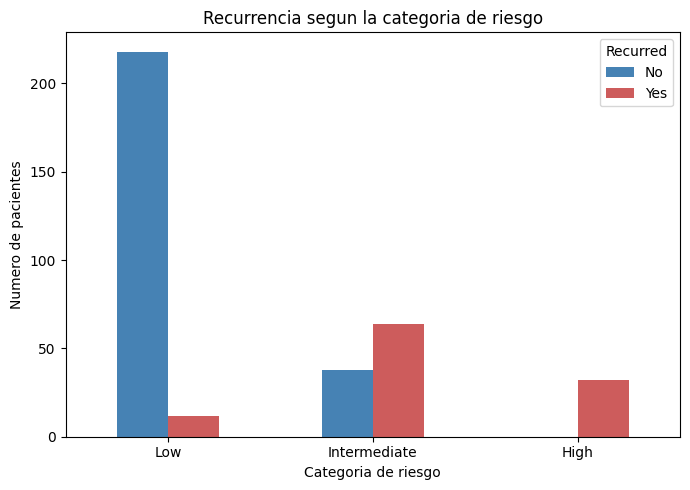

Recurred         No    Yes
Risk                      
High          0.000  1.000
Intermediate  0.373  0.627
Low           0.948  0.052

In [13]:
tabla_riesgo = pd.crosstab(df['Risk'], df['Recurred'])
tabla_riesgo = tabla_riesgo.reindex(['Low', 'Intermediate', 'High'])

tabla_riesgo.plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('Recurrencia segun la categoria de riesgo')
plt.xlabel('Categoria de riesgo')
plt.ylabel('Numero de pacientes')
plt.xticks(rotation=0)
plt.legend(title='Recurred')
plt.tight_layout()
plt.show()

print(pd.crosstab(df['Risk'], df['Recurred'], normalize='index').round(3))

**Interpretación:** la categoría de riesgo asignada por el equipo clínico separa las clases de forma muy marcada. En riesgo bajo (230 pacientes) solo el 5.2% recurre; en riesgo intermedio la tasa sube al 62.7%; y en riesgo alto (32 pacientes) recurren **todos**. La relación es monótona y muy fuerte, lo que anticipa que `Risk` será una de las variables más importantes para cualquier modelo.

*Como responsable de la toma de decisiones,* recomiendo que la variable `Risk` se conserve en el modelo pero que el resultado se lea con cuidado: al ser una categoría asignada por médicos que ya observaron al paciente, resume conocimiento clínico previo. El modelo va a apoyarse fuertemente en ella, y eso significa que su utilidad práctica es apoyar y estandarizar la decisión de seguimiento, no reemplazar la evaluación clínica.

### 8.2 Gráfica de pie — distribución de la variable objetivo

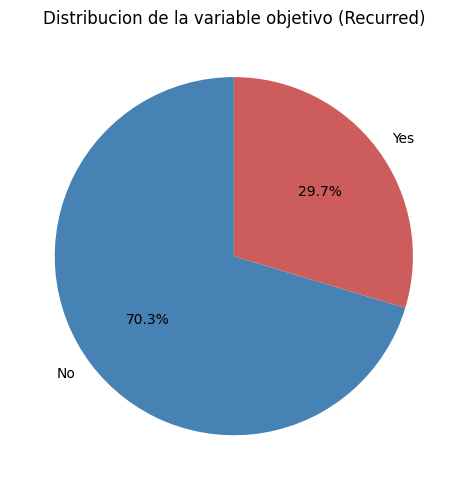

Recurred
No     256
Yes    108
Name: count, dtype: int64


In [14]:
conteo = df['Recurred'].value_counts()

plt.pie(conteo, labels=conteo.index, autopct='%1.1f%%',
        colors=['steelblue', 'indianred'], startangle=90)
plt.title('Distribucion de la variable objetivo (Recurred)')
plt.tight_layout()
plt.show()

print(conteo)

**Interpretación:** el 70.3% de los pacientes (256) no presentó recurrencia y el 29.7% (108) sí. El desbalance existe pero es moderado: no estamos en un escenario extremo tipo 99/1. Aun así, es suficiente para que el *accuracy* por sí solo sea una métrica engañosa: un modelo que prediga siempre "No recurre" acertaría el 70.3% de las veces sin haber aprendido nada útil, y fallaría en el 100% de los pacientes que sí necesitaban seguimiento estrecho.

*Como responsable de la toma de decisiones,* recomiendo dos cosas: estratificar las particiones de train/validation/test por la variable objetivo para que las tres conserven esta proporción, y fijar desde ahora que la métrica principal de comparación será el **recall de la clase `Yes`** acompañado del F1, usando el 70.3% como línea base mínima que cualquier modelo debe superar con holgura.

### 8.3 Histograma — distribución de la edad

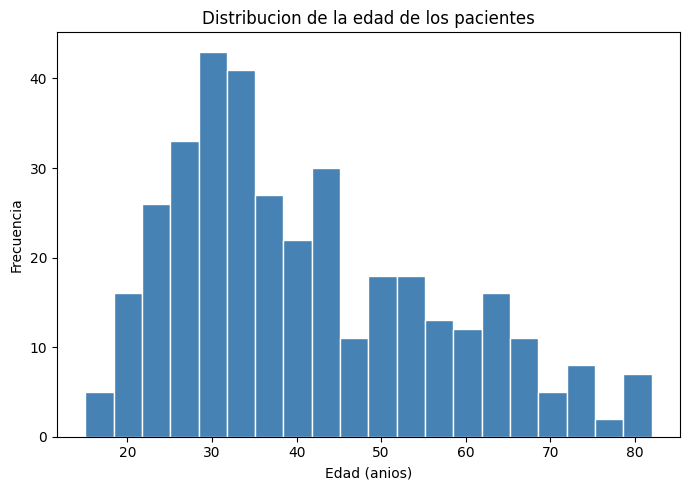

count    364.00
mean      41.25
std       15.31
min       15.00
25%       30.00
50%       38.00
75%       52.00
max       82.00
Name: Age, dtype: float64


In [15]:
plt.hist(df['Age'], bins=20, color='steelblue', edgecolor='white')
plt.title('Distribucion de la edad de los pacientes')
plt.xlabel('Edad (anios)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

print(df['Age'].describe().round(2))

**Interpretación:** la distribución de la edad es unimodal con un pico entre los 25 y los 40 años y una cola hacia la derecha que se extiende hasta los 82 años. Confirma visualmente lo que ya indicaban los estadísticos del punto 3 (media 41.2 > mediana 38.0). No se observan barras aisladas en valores imposibles, lo que respalda que la columna está limpia.

*Como responsable de la toma de decisiones,* recomiendo mantener la edad como variable continua sin agruparla en rangos: la forma de la distribución es suave y agruparla en categorías ("joven", "adulto", "mayor") destruiría información sin ninguna ganancia. La cola derecha, además, justifica la decisión ya tomada de imputar por mediana en lugar de media.

### 8.4 Diagrama de dispersión — edad frente a estadio T

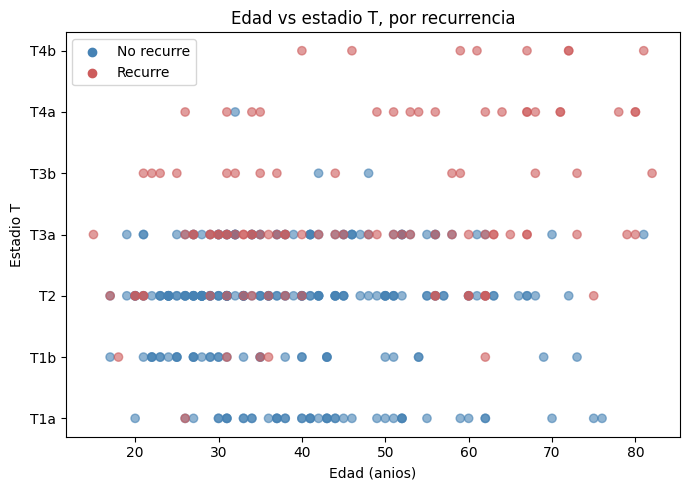

In [16]:
orden_t = ['T1a', 'T1b', 'T2', 'T3a', 'T3b', 'T4a', 'T4b']
t_num = df['T'].map({v: i for i, v in enumerate(orden_t)})

colores = df['Recurred'].map({'No': 'steelblue', 'Yes': 'indianred'})
plt.scatter(df['Age'], t_num, c=colores, alpha=0.6)
plt.yticks(range(len(orden_t)), orden_t)
plt.title('Edad vs estadio T, por recurrencia')
plt.xlabel('Edad (anios)')
plt.ylabel('Estadio T')
plt.scatter([], [], c='steelblue', label='No recurre')
plt.scatter([], [], c='indianred', label='Recurre')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:** este dataset tiene una sola variable continua, así que para el diagrama de dispersión se usó `Age` en el eje X y el estadio `T` codificado ordinalmente en el eje Y, coloreando por la variable objetivo. Se observa que los puntos rojos (recurrencia) se concentran en la parte superior del gráfico: a partir de T3b prácticamente no hay puntos azules, mientras que en T1a y T1b casi todos los pacientes son azules sin importar la edad. En el eje horizontal la separación es mucho menos clara, aunque los pacientes mayores de 60 años muestran más presencia de rojo incluso en estadios bajos.

*Como responsable de la toma de decisiones,* recomiendo priorizar el estadio T sobre la edad como criterio de seguimiento intensivo: la gráfica muestra que el tamaño e invasión del tumor discrimina mucho mejor que la edad. La edad aporta información complementaria, no principal, y por eso conviene dejar que el modelo la combine con el resto de variables en lugar de definir reglas por edad.

### 8.5 Boxplot — edad según recurrencia

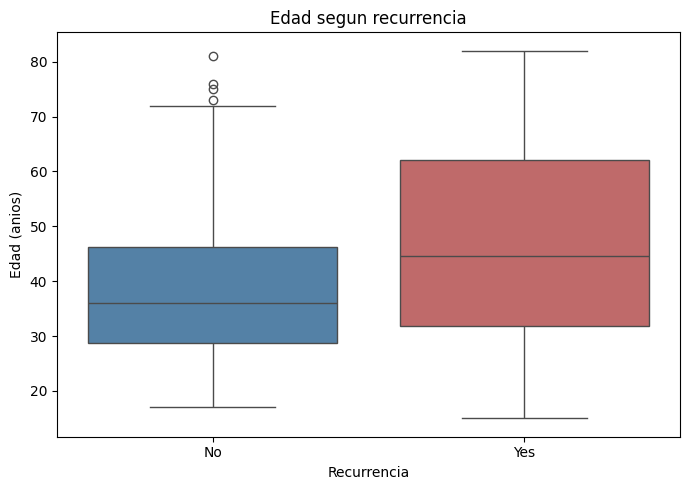

          count  mean   std   min   25%   50%   75%   max
Recurred                                                 
No        256.0  38.8  13.2  17.0  28.8  36.0  46.2  81.0
Yes       108.0  47.1  18.3  15.0  31.8  44.5  62.0  82.0


In [17]:
sns.boxplot(data=df, x='Recurred', y='Age', hue='Recurred',
            palette=['steelblue', 'indianred'], legend=False)
plt.title('Edad segun recurrencia')
plt.xlabel('Recurrencia')
plt.ylabel('Edad (anios)')
plt.tight_layout()
plt.show()

print(df.groupby('Recurred')['Age'].describe().round(1))

**Interpretación:** los pacientes con recurrencia son en promedio mayores (media 47.1 años, mediana 44.5) que los que no recurren (media 38.8, mediana 36.0), y además su caja es notablemente más ancha: el rango intercuartílico va de 31.8 a 62.0 años frente a 28.8–46.2 en el grupo sin recurrencia. Las cajas se solapan bastante, así que la edad por sí sola **no separa** las clases, pero desplaza la probabilidad en la dirección esperada clínicamente.

El gráfico marca además cuatro pacientes de más de 72 años como puntos fuera de los bigotes dentro del grupo sin recurrencia. Esto no contradice el punto 7: allí el criterio IQR se aplicó sobre la columna `Age` completa, mientras que el boxplot lo calcula dentro de cada grupo, donde la caja es más estrecha. Siguen siendo edades perfectamente posibles y se conservan.

*Como responsable de la toma de decisiones,* recomiendo no usar la edad como criterio único de tamizaje —un umbral de edad dejaría escapar muchos casos jóvenes que sí recurren— pero sí incluirla en el modelo, y usar este gráfico para justificar ante el equipo clínico por qué un paciente joven con estadio avanzado no debe ser dado de alta del seguimiento solo por su edad.

## 9. Técnica de codificación por variable categórica

Antes de decidir hay que tener presentes dos restricciones del problema: **(a)** vamos a entrenar KNN, que es un modelo basado en distancias y por lo tanto sí interpreta como "cercanos" a los valores numéricos cercanos; y **(b)** después de eliminar duplicados quedan 364 filas, de las cuales solo ~254 serán de entrenamiento. Con tan pocas filas, inflar la dimensionalidad con One-Hot en todas las columnas perjudica directamente a KNN (maldición de la dimensionalidad).

Con eso en mente, la decisión columna por columna es:

| Variable | Cardinalidad | ¿Orden natural? | Técnica elegida | Justificación |
|---|---|---|---|---|
| `Gender` | 2 | No | One-Hot | Nominal. Con 2 categorías One-Hot agrega solo 2 columnas y no introduce ningún orden. |
| `Smoking` | 2 | No | One-Hot | Igual que la anterior. |
| `Hx Smoking` | 2 | No | One-Hot | Igual que la anterior. |
| `Hx Radiothreapy` | 2 | No | One-Hot | Igual que la anterior. |
| `Thyroid Function` | 5 | No | One-Hot | Hiper e hipotiroidismo son alteraciones en direcciones opuestas: no existe una escala que las ordene, cualquier número que se les asigne sería arbitrario. |
| `Physical Examination` | 5 | No | One-Hot | Bocio uninodular izquierdo, derecho, multinodular o difuso son ubicaciones, no niveles. |
| `Adenopathy` | 6 | No | One-Hot | Es la ubicación de los ganglios comprometidos (derecha, izquierda, bilateral…). El compromiso ganglionar como *nivel* ya está capturado por `N`. |
| `Pathology` | 4 | No | One-Hot | Tipos histológicos distintos, sin jerarquía numérica. |
| `Focality` | 2 | No | One-Hot | Unifocal / multifocal, dos categorías. |
| `M` | 2 | No | One-Hot | M0 / M1. Aunque M1 es peor que M0, con solo 2 categorías One-Hot y Ordinal son equivalentes en información, y One-Hot mantiene la coherencia con el resto de binarias. |
| `Response` | 4 | Discutible | One-Hot | La respuesta al tratamiento tiene un orden clínico defendible (excelente → indeterminada → incompleta bioquímica → incompleta estructural), pero las distancias entre niveles no son comparables y el orden no es universalmente aceptado. Con solo 4 categorías, One-Hot cuesta poco y evita imponer un orden discutible. |
| `Risk` | 3 | **Sí** | **Ordinal** | Low < Intermediate < High es un orden clínico explícito y bien definido. |
| `T` | 7 | **Sí** | **Ordinal** | El estadiaje TNM es ordinal por construcción: T1a < T1b < T2 < T3a < T3b < T4a < T4b. Además es la categórica de mayor cardinalidad: codificarla One-Hot agregaría 7 columnas para 254 filas de entrenamiento. |
| `N` | 3 | **Sí** | **Ordinal** | N0 < N1a < N1b indica compromiso ganglionar creciente. |
| `Stage` | 5 | **Sí** | **Ordinal** | I < II < III < IVA < IVB es el estadio final, ordinal por definición. |

**Resumen de la decisión:** One-Hot para las 11 variables nominales y Ordinal (con el orden clínico declarado explícitamente, no el alfabético por defecto) para `Risk`, `T`, `N` y `Stage`.

La advertencia del enunciado sobre el "orden falso" del Label/Ordinal Encoding aplica cuando la variable **no** tiene orden. En estas cuatro variables el orden existe y está definido por el estadiaje TNM, así que codificarlas ordinalmente no inventa información: la preserva. El beneficio adicional es que la matriz de entrada pasa de 55 a 41 columnas, lo que ayuda a KNN.

**Variable objetivo:** `Recurred` se codifica manualmente como `No = 0` y `Yes = 1`. Con exactamente dos categorías este mapeo no introduce ningún orden falso, y deja `Yes` como clase positiva (1), que es la convención que usan `precision_score`, `recall_score` y `f1_score` por defecto.

## 10. Escalamiento de las variables numéricas

**Sí es necesario escalar**, y la razón es el conjunto de modelos que vamos a entrenar:

- **KNN** clasifica por distancia euclidiana. Sin escalar, `Age` toma valores entre 15 y 82 mientras que las columnas One-Hot valen 0 o 1: la distancia entre dos pacientes quedaría dominada casi por completo por la diferencia de edad, y todas las variables clínicas serían prácticamente ignoradas. Escalar es indispensable aquí.
- **Árbol de Decisión, Random Forest y Gradient Boosting** son insensibles a la escala, porque parten por umbrales sobre cada variable de forma independiente y un umbral se reescala junto con los datos. Escalar no los perjudica ni los mejora.

Como usamos un único `ColumnTransformer` para los cuatro modelos, escalar es la opción correcta: es necesario para uno de ellos e inofensivo para los otros tres.

**Técnica elegida: `StandardScaler`.** La justificación se apoya directamente en el punto 7: `Age` no tiene ningún outlier según el criterio IQR, por lo que la media y la desviación estándar son estimadores confiables y **no hace falta `RobustScaler`**, que solo se justifica cuando hay valores extremos que distorsionan esos estadísticos. Frente a `MinMaxScaler`, `StandardScaler` es preferible porque MinMax comprime todo al rango [0,1] usando el mínimo y el máximo observados, dos valores que dependen de un solo paciente cada uno; con 254 filas de entrenamiento eso lo hace frágil.

También se escalan las cuatro variables ordinales después de codificarlas. Si no se hiciera, `T` quedaría en el rango 0–6 y `N` en 0–2, y KNN le daría tres veces más peso a `T` solo por el rango de su codificación. Las columnas One-Hot no se escalan: ya están en 0/1, que es el mismo orden de magnitud que produce el escalado.

---
# Fase 2 — División de datos y Pipelines

## 11. División en train / validation / test (70 / 15 / 15)

In [18]:
y = df['Recurred'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Recurred'])

# Primer corte: 70% entrenamiento, 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=random_state)

# Segundo corte: el 30% temporal se parte por la mitad -> 15% validacion, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=random_state)

print("Train:      ", X_train.shape, "| proporcion de recurrencia:", round(y_train.mean(), 3))
print("Validation: ", X_val.shape, "| proporcion de recurrencia:", round(y_val.mean(), 3))
print("Test:       ", X_test.shape, "| proporcion de recurrencia:", round(y_test.mean(), 3))

Train:       (254, 16) | proporcion de recurrencia: 0.295
Validation:  (55, 16) | proporcion de recurrencia: 0.309
Test:        (55, 16) | proporcion de recurrencia: 0.291


**Propósito de cada conjunto:**

- **Train (254 filas):** es el único conjunto del que el modelo aprende. Sobre él se ajustan tanto los parámetros de los modelos como los parámetros de las transformaciones (la media y desviación del escalador, las categorías del encoder, los valores de imputación).
- **Validation (55 filas):** sirve para comparar modelos entre sí y para detectar overfitting. El modelo no aprende de este conjunto, pero **nosotros sí tomamos decisiones a partir de él**: es aquí donde miramos las métricas para decidir cuál de los cuatro algoritmos es el mejor.
- **Test (55 filas):** se guarda sin tocar hasta la Fase 6. Es la estimación honesta de cómo se comportaría el modelo con pacientes nuevos.

**¿Por qué no basta con train/test?** Porque si usáramos el conjunto de test para elegir el mejor modelo, ese conjunto dejaría de ser "datos nunca vistos". Al comparar cuatro algoritmos sobre el mismo conjunto y quedarnos con el mejor, estaríamos ajustando nuestra decisión a las particularidades de esas 55 filas; el número que reportáramos sería optimista, porque incluiría la suerte de que ese modelo en particular funcionara bien justo ahí. Separar validación de test permite que la decisión se tome en un conjunto y el reporte final se haga en otro, que sí permaneció aislado de todo el proceso.

Se usó `stratify` en ambos cortes para que la proporción de recurrencia (~29.7%) se mantenga en los tres conjuntos, tal como se recomendó en el punto 8.2. Con solo 55 filas por conjunto, sin estratificar una partición podría quedar con muy pocos casos positivos y las métricas serían inestables.

## 12. Pipeline con ColumnTransformer

In [19]:
col_numericas = ['Age']
col_ordinales = ['Risk', 'T', 'N', 'Stage']
col_nominales = [c for c in X_train.columns if c not in col_numericas + col_ordinales]

ordenes = [
    ['Low', 'Intermediate', 'High'],                              # Risk
    ['T1a', 'T1b', 'T2', 'T3a', 'T3b', 'T4a', 'T4b'],             # T
    ['N0', 'N1a', 'N1b'],                                         # N
    ['I', 'II', 'III', 'IVA', 'IVB']                              # Stage
]

print("Numericas:", col_numericas)
print("Ordinales:", col_ordinales)
print("Nominales:", col_nominales)

Numericas: ['Age']
Ordinales: ['Risk', 'T', 'N', 'Stage']
Nominales: ['Gender', 'Smoking', 'Hx Smoking', 'Hx Radiothreapy', 'Thyroid Function', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'M', 'Response']


In [20]:
transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_ordinal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=ordenes)),
    ('scaler', StandardScaler())
])

transformador_nominal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', transformador_numerico, col_numericas),
    ('ord', transformador_ordinal, col_ordinales),
    ('cat', transformador_nominal, col_nominales)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [21]:
X_train_transformado = preprocessor.fit_transform(X_train)
print("Forma de X_train despues del preprocesamiento:", X_train_transformado.shape)
print("Columnas originales:", X_train.shape[1], "-> columnas transformadas:", X_train_transformado.shape[1])

Forma de X_train despues del preprocesamiento: (254, 41)
Columnas originales: 16 -> columnas transformadas: 41


El `ColumnTransformer` aplica en paralelo las tres rutas definidas en la Fase 1 y concatena los resultados: imputación por mediana + `StandardScaler` para `Age`; imputación por moda + `OrdinalEncoder` con el orden clínico declarado + `StandardScaler` para las cuatro ordinales; e imputación por moda + `OneHotEncoder` para las once nominales. `handle_unknown='ignore'` evita que el pipeline falle si en validación o test aparece una categoría que no estaba en entrenamiento (algo posible con categorías raras como `Adenopathy = Posterior`, que solo tiene 2 casos).

Las 16 columnas de entrada se convierten en 41: 1 numérica + 4 ordinales + 36 columnas One-Hot.

## 13. Verificación de que no hay fuga de datos (data leakage)

**Argumento:** en este notebook todas las transformaciones que aprenden de los datos (el imputador, el escalador y los dos encoders) viven **dentro** del `ColumnTransformer`, que a su vez vive dentro de un `Pipeline` junto con el clasificador. Cuando se llama `pipeline.fit(X_train, y_train)`, scikit-learn ejecuta `.fit_transform()` de cada transformación **únicamente sobre `X_train`**. Cuando después se llama `pipeline.predict(X_val)` o `pipeline.predict(X_test)`, scikit-learn ejecuta solo `.transform()` con los parámetros ya aprendidos: no vuelve a llamar `.fit()` en ningún momento. En ninguna celda de este notebook se llama `.fit()` con `X_val` o con `X_test`.

Esto importa porque si el escalador hubiera calculado su media usando todo el dataset, esa media contendría información de los pacientes de test, y el modelo estaría siendo evaluado con datos que ya "conoce" indirectamente. Lo mismo pasaría con el imputador (imputaría usando estadísticos contaminados) y con el encoder (conocería categorías que no debía haber visto).

La celda siguiente lo comprueba numéricamente: la media y la desviación que guardó el escalador coinciden con las de `X_train` y **no** con las del dataset completo.

In [22]:
scaler_ajustado = preprocessor.named_transformers_['num'].named_steps['scaler']

print("Media guardada por el scaler:      ", round(scaler_ajustado.mean_[0], 4))
print("Media de Age en X_train:           ", round(X_train['Age'].mean(), 4))
print("Media de Age en el dataset completo:", round(df['Age'].mean(), 4))
print()
print("Desviacion guardada por el scaler: ", round(scaler_ajustado.scale_[0], 4))
print("Desviacion de Age en X_train:      ", round(X_train['Age'].std(ddof=0), 4))
print()
print("Numero de filas usadas para ajustar el preprocesador:", scaler_ajustado.n_samples_seen_)
print("Numero de filas de X_train:                          ", X_train.shape[0])

Media guardada por el scaler:       41.0354
Media de Age en X_train:            41.0354
Media de Age en el dataset completo: 41.25

Desviacion guardada por el scaler:  15.5286
Desviacion de Age en X_train:       15.5286

Numero de filas usadas para ajustar el preprocesador: 254.0
Numero de filas de X_train:                           254


Los valores confirman lo anterior: el escalador vio exactamente 254 filas (las de `X_train`) y su media coincide con la de `X_train`, no con la del dataset completo. Sobre `X_val` y `X_test` solo se aplicará `.transform()` a través del pipeline.

---
# Fase 4 — Modelado: Clasificación

## 16. Entrenamiento de los modelos

In [23]:
modelos = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Arbol de Decision': DecisionTreeClassifier(random_state=random_state),
    'Random Forest': RandomForestClassifier(random_state=random_state),
    'Gradient Boosting': GradientBoostingClassifier(random_state=random_state)
}

pipelines = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', modelo)])
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe
    print(nombre, "-> entrenado")

KNN -> entrenado
Arbol de Decision -> entrenado


Random Forest -> entrenado


Gradient Boosting -> entrenado


Los cuatro modelos se entrenan con los hiperparámetros por defecto de scikit-learn (KNN con k=5, y los tres modelos de árboles sin límite de profundidad). El enunciado no pide búsqueda de hiperparámetros, y dejarlos por defecto tiene además una ventaja para el análisis del punto 19: un árbol sin podar es el caso de libro de overfitting, y verlo explícitamente en las métricas es parte de lo que se pide analizar.

Se fija `random_state=42` en los tres modelos que tienen componente aleatorio para que los resultados sean reproducibles.

## 17. Predicciones sobre el conjunto de validación

In [24]:
predicciones_val = {}
for nombre, pipe in pipelines.items():
    predicciones_val[nombre] = pipe.predict(X_val)

pd.DataFrame(predicciones_val, index=X_val.index).head(10)

,KNN,Arbol de Decision,Random Forest,Gradient Boosting
283,1,1,1,1
289,1,1,1,1
342,1,1,1,1
220,0,1,1,1
37,0,0,0,0
169,0,0,0,0
163,0,0,0,0
344,1,1,1,1
137,0,0,0,0
1,0,0,0,0


La tabla muestra las predicciones de los cuatro modelos sobre los primeros 10 pacientes del conjunto de validación (0 = no recurre, 1 = recurre). Se puede ver que los modelos coinciden en la mayoría de los casos y difieren en unos pocos, que son justamente los que van a explicar las diferencias de métricas del punto 19.

---
# Fase 5 — Métricas en train y validación: detección de overfitting/underfitting

## 19. Métricas y matrices de confusión

In [25]:
def calcular_metricas(y_real, y_pred):
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision': precision_score(y_real, y_pred, zero_division=0),
        'Recall': recall_score(y_real, y_pred, zero_division=0),
        'F1': f1_score(y_real, y_pred, zero_division=0)
    }

for nombre, pipe in pipelines.items():
    m_train = calcular_metricas(y_train, pipe.predict(X_train))
    m_val = calcular_metricas(y_val, predicciones_val[nombre])
    print("=" * 60)
    print(nombre)
    print("  TRAIN ->", {k: round(v, 3) for k, v in m_train.items()})
    print("  VAL   ->", {k: round(v, 3) for k, v in m_val.items()})
    print("  Matriz de confusion (validacion), filas=real, columnas=predicho:")
    print(confusion_matrix(y_val, predicciones_val[nombre]))

KNN
  TRAIN -> {'Accuracy': 0.937, 'Precision': 0.954, 'Recall': 0.827, 'F1': 0.886}
  VAL   -> {'Accuracy': 0.891, 'Precision': 0.867, 'Recall': 0.765, 'F1': 0.812}
  Matriz de confusion (validacion), filas=real, columnas=predicho:
[[36  2]
 [ 4 13]]
Arbol de Decision
  TRAIN -> {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
  VAL   -> {'Accuracy': 0.909, 'Precision': 0.8, 'Recall': 0.941, 'F1': 0.865}
  Matriz de confusion (validacion), filas=real, columnas=predicho:
[[34  4]
 [ 1 16]]
Random Forest
  TRAIN -> {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
  VAL   -> {'Accuracy': 0.964, 'Precision': 0.941, 'Recall': 0.941, 'F1': 0.941}
  Matriz de confusion (validacion), filas=real, columnas=predicho:
[[37  1]
 [ 1 16]]
Gradient Boosting
  TRAIN -> {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
  VAL   -> {'Accuracy': 0.927, 'Precision': 0.842, 'Recall': 0.941, 'F1': 0.889}
  Matriz de confusion (validacion), filas=real, columnas=predicho:

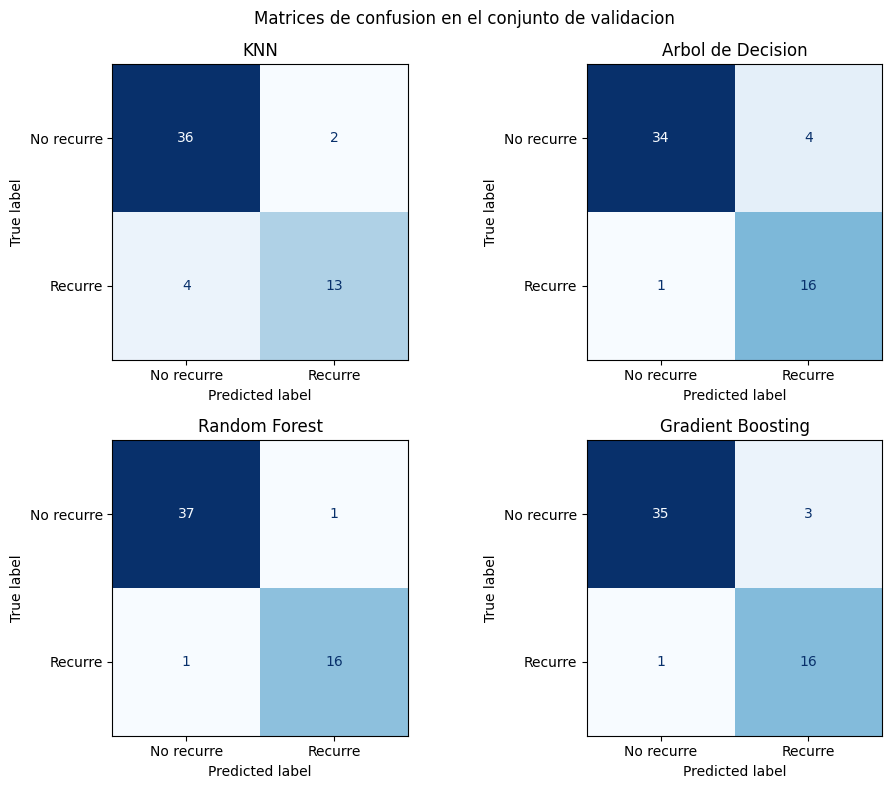

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (nombre, pipe) in zip(axes.flatten(), pipelines.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val, predicciones_val[nombre],
        display_labels=['No recurre', 'Recurre'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
fig.suptitle('Matrices de confusion en el conjunto de validacion')
plt.tight_layout()
plt.show()

### Comparación train vs validación: overfitting / underfitting

- **KNN (k=5).** Es el único que no memoriza el entrenamiento: accuracy 0.937 en train y 0.891 en validación, una caída pequeña. Pero su problema está en el recall: 0.827 en train y **0.765 en validación**, el más bajo de los cuatro. Es decir, no está sobreajustado, pero sí es el modelo que más pacientes con recurrencia deja pasar (4 de 17 en validación). Esto es consistente con lo esperado: KNN mide distancias en un espacio de 41 dimensiones donde 36 son variables binarias, y con 254 pacientes de entrenamiento los "vecinos" no son tan informativos como en un espacio de pocas variables continuas.

- **Árbol de Decisión.** Métricas **perfectas en train (1.000 en las cuatro)** y 0.909 de accuracy en validación, con F1 de 0.865. Es la señal clásica de **overfitting**: al no limitar la profundidad, el árbol crece hasta aislar cada paciente de entrenamiento en su propia hoja. Lo interesante es que aun así generaliza aceptablemente, porque las variables clínicas del dataset son muy informativas. En validación produce 4 falsos positivos, la cifra más alta junto con Gradient Boosting.

- **Random Forest.** También llega a 1.000 en train, así que técnicamente sobreajusta; sin embargo la caída en validación es la más pequeña de todas (accuracy 0.964, F1 0.941, con un único falso positivo y un único falso negativo de 55 pacientes). Esto ilustra lo visto en clase: cada árbol del bosque sobreajusta, pero al promediar árboles entrenados sobre muestras bootstrap distintas y con subconjuntos aleatorios de variables, la varianza se reduce y el conjunto generaliza mucho mejor que un árbol solo.

- **Gradient Boosting.** Mismo patrón: 1.000 en train y 0.927 de accuracy en validación con F1 de 0.889. Iguala a Random Forest en recall (0.941) pero comete 3 falsos positivos en lugar de 1, lo que baja su precisión a 0.842.

**Ningún modelo presenta underfitting**: los cuatro superan ampliamente el 70.3% de accuracy que obtendría un clasificador que siempre respondiera "no recurre", y ninguno tiene desempeño pobre simultáneamente en train y validación.

### Interpretación clínica: ¿falso positivo o falso negativo?

En este problema los dos errores no cuestan lo mismo:

- Un **falso positivo** es un paciente que en realidad no va a recurrir y al que el modelo marca como de alto riesgo. La consecuencia es un seguimiento más intensivo del necesario: más ecografías, más mediciones de tiroglobulina, más consultas. Cuesta dinero y genera ansiedad, pero es **reversible** y no pone en peligro al paciente.
- Un **falso negativo** es un paciente que sí va a recurrir y al que el modelo declara de bajo riesgo. La consecuencia es que se le espacia el seguimiento y la recurrencia se detecta tarde, cuando el tumor ya creció o se diseminó. Es un error **mucho más costoso** y potencialmente irreversible.

Por lo tanto, la métrica que debe priorizarse es el **recall de la clase `Yes`** (sensibilidad), que mide qué fracción de los pacientes que efectivamente recurrieron fue detectada. El accuracy no sirve como criterio principal por el desbalance del 70/30, y la precisión sola tampoco, porque un modelo puede tener precisión perfecta prediciendo "recurre" en muy pocos casos y dejando escapar a la mayoría. La métrica de acompañamiento es el **F1**, que evita el extremo opuesto: un modelo que marcara a todos como recurrentes tendría recall 1.0 pero sería inservible en la práctica.

Con ese criterio, en validación Random Forest y Gradient Boosting y el Árbol de Decisión empatan en recall (0.941, es decir 16 de 17 pacientes detectados), y Random Forest se impone porque logra ese mismo recall con un solo falso positivo.

## 20. Tabla comparativa (train y validación)

In [27]:
filas = []
for nombre, pipe in pipelines.items():
    m_train = calcular_metricas(y_train, pipe.predict(X_train))
    m_val = calcular_metricas(y_val, predicciones_val[nombre])
    fila = {'Modelo': nombre}
    for k, v in m_train.items():
        fila[k + ' (train)'] = v
    for k, v in m_val.items():
        fila[k + ' (val)'] = v
    filas.append(fila)

tabla_val = pd.DataFrame(filas).set_index('Modelo').round(3)
tabla_val

,Accuracy (train),Precision (train),Recall (train),F1 (train),Accuracy (val),Precision (val),Recall (val),F1 (val)
Modelo,,,,,,,,
KNN,0.937,0.954,0.827,0.886,0.891,0.867,0.765,0.812
Arbol de Decision,1.000,1.000,1.000,1.000,0.909,0.800,0.941,0.865
Random Forest,1.000,1.000,1.000,1.000,0.964,0.941,0.941,0.941
Gradient Boosting,1.000,1.000,1.000,1.000,0.927,0.842,0.941,0.889


## 21. Selección del mejor modelo

**Modelo seleccionado: Random Forest.**

La elección no se basa solo en que tenga el F1 más alto en validación (0.941). El razonamiento completo es:

1. **Recall.** Empata en el recall más alto (0.941, 16 de 17 recurrencias detectadas) con el Árbol de Decisión y con Gradient Boosting. Como se argumentó en el punto 19, esta es la métrica prioritaria por el costo clínico del falso negativo. KNN queda descartado aquí: 0.765 de recall significa que deja pasar uno de cada cuatro pacientes que sí recurren.

2. **Precisión con el mismo recall.** Con el recall empatado, el desempate es la precisión: Random Forest logra ese recall con **1 solo falso positivo**, frente a 3 de Gradient Boosting y 4 del Árbol. Es decir, alcanza la misma capacidad de detección generando menos seguimiento innecesario.

3. **Señal de over/underfitting.** Los tres modelos de árboles llegan a 1.000 en train, pero la brecha train→validación es la más estrecha en Random Forest (1.000 → 0.964 de accuracy) y más amplia en el Árbol individual (1.000 → 0.909) y en Gradient Boosting (1.000 → 0.927). El bagging del Random Forest está cumpliendo su función de reducir varianza, mientras que el árbol único depende demasiado de los datos particulares que recibió.

4. **Trade-offs.**
   - *Interpretabilidad:* aquí el Árbol de Decisión gana claramente, porque su estructura se puede leer y explicar a un médico regla por regla. Random Forest es una caja más opaca, aunque conserva la importancia de variables. Se acepta esta pérdida porque el modelo se plantea como apoyo a la decisión de seguimiento, no como el criterio único, y porque el árbol solo tiene un desempeño claramente inferior.
   - *Tiempo de entrenamiento:* con 254 filas los cuatro modelos entrenan en menos de un segundo, así que el costo computacional no es un criterio de decisión en este problema. En un dataset grande sí lo sería, y ahí Random Forest tiene la ventaja adicional de que sus árboles se pueden entrenar en paralelo, mientras que Gradient Boosting es secuencial por construcción (cada árbol corrige el error del anterior).
   - *Sensibilidad a hiperparámetros:* Gradient Boosting suele necesitar ajuste de `learning_rate` y `n_estimators` para rendir bien; Random Forest funciona razonablemente con valores por defecto, que es exactamente lo que se observa aquí.

**Advertencia sobre el tamaño de la muestra:** el conjunto de validación tiene 55 pacientes, de los cuales 17 recurrieron. Un solo paciente mal clasificado mueve el accuracy 1.8 puntos porcentuales y el recall casi 6 puntos. La diferencia entre Random Forest (F1 0.941) y Gradient Boosting (F1 0.889) equivale a **dos pacientes**. Por eso la selección se confirma con validación cruzada en la Fase 7 en lugar de darla por definitiva con este único split.

---
# Fase 6 — Evaluación final en el conjunto de Test

## 22. Evaluación de todos los modelos sobre test

In [28]:
for nombre, pipe in pipelines.items():
    y_pred_test = pipe.predict(X_test)
    m_test = calcular_metricas(y_test, y_pred_test)
    print("=" * 60)
    print(nombre)
    print("  TEST ->", {k: round(v, 3) for k, v in m_test.items()})
    print("  Matriz de confusion (test), filas=real, columnas=predicho:")
    print(confusion_matrix(y_test, y_pred_test))

KNN
  TEST -> {'Accuracy': 0.964, 'Precision': 0.938, 'Recall': 0.938, 'F1': 0.938}
  Matriz de confusion (test), filas=real, columnas=predicho:
[[38  1]
 [ 1 15]]
Arbol de Decision
  TEST -> {'Accuracy': 0.927, 'Precision': 0.833, 'Recall': 0.938, 'F1': 0.882}
  Matriz de confusion (test), filas=real, columnas=predicho:
[[36  3]
 [ 1 15]]
Random Forest
  TEST -> {'Accuracy': 0.945, 'Precision': 0.933, 'Recall': 0.875, 'F1': 0.903}
  Matriz de confusion (test), filas=real, columnas=predicho:
[[38  1]
 [ 2 14]]
Gradient Boosting
  TEST -> {'Accuracy': 0.964, 'Precision': 0.938, 'Recall': 0.938, 'F1': 0.938}
  Matriz de confusion (test), filas=real, columnas=predicho:
[[38  1]
 [ 1 15]]


## 23. Tabla comparativa final y comparación con validación

In [29]:
filas_test = []
for nombre, pipe in pipelines.items():
    m_test = calcular_metricas(y_test, pipe.predict(X_test))
    filas_test.append({'Modelo': nombre, **m_test})

tabla_test = pd.DataFrame(filas_test).set_index('Modelo').round(3)
tabla_test

,Accuracy,Precision,Recall,F1
Modelo,,,,
KNN,0.964,0.938,0.938,0.938
Arbol de Decision,0.927,0.833,0.938,0.882
Random Forest,0.945,0.933,0.875,0.903
Gradient Boosting,0.964,0.938,0.938,0.938


In [30]:
comparacion = pd.DataFrame({
    'F1 (val)': tabla_val['F1 (val)'],
    'F1 (test)': tabla_test['F1'],
    'Recall (val)': tabla_val['Recall (val)'],
    'Recall (test)': tabla_test['Recall'],
    'Accuracy (val)': tabla_val['Accuracy (val)'],
    'Accuracy (test)': tabla_test['Accuracy']
}).round(3)

comparacion['Ranking val (F1)'] = comparacion['F1 (val)'].rank(ascending=False).astype(int)
comparacion['Ranking test (F1)'] = comparacion['F1 (test)'].rank(ascending=False).astype(int)
comparacion

,F1 (val),F1 (test),Recall (val),Recall (test),Accuracy (val),Accuracy (test),Ranking val (F1),Ranking test (F1)
Modelo,,,,,,,,
KNN,0.812,0.938,0.765,0.938,0.891,0.964,4,1
Arbol de Decision,0.865,0.882,0.941,0.938,0.909,0.927,3,4
Random Forest,0.941,0.903,0.941,0.875,0.964,0.945,1,3
Gradient Boosting,0.889,0.938,0.941,0.938,0.927,0.964,2,1


**¿Se mantiene el ranking?** No, y esa es la observación más importante de esta fase. En validación el orden por F1 era Random Forest (0.941) > Gradient Boosting (0.889) > Árbol (0.865) > KNN (0.812). En test el orden se reordena: KNN y Gradient Boosting empatan primeros (0.938), Random Forest queda tercero (0.903) y el Árbol último (0.882). El cambio más llamativo es KNN, que pasa del último lugar al primero.

**¿Son consistentes las métricas del mejor modelo?** El Random Forest obtuvo accuracy 0.964 y F1 0.941 en validación, frente a accuracy 0.945 y F1 0.903 en test. En términos absolutos la diferencia parece pequeña, pero conviene traducirla a pacientes: en validación falló 2 de 55, en test falló 3 de 55. Su recall bajó de 0.941 a 0.875, lo que en términos concretos significa pasar de 1 falso negativo (de 17 recurrencias) a 2 falsos negativos (de 16). **Es la diferencia de un solo paciente.**

**¿Qué significaría una diferencia grande entre validación y test?** Normalmente una de tres cosas: (a) que el modelo se sobreajustó al conjunto de validación, porque lo usamos repetidamente para elegir y ajustar; (b) que los conjuntos no son comparables, por ejemplo si la partición no fue estratificada y quedaron proporciones muy distintas de la clase positiva; o (c) que los conjuntos son tan pequeños que las métricas tienen mucha varianza y el "mejor modelo" cambia según el sorteo.

En este caso la explicación es claramente **(c)**. Con 55 pacientes por conjunto, un solo error mueve el accuracy 1.8 puntos y el recall unos 6 puntos, y todo el reordenamiento del ranking se explica por diferencias de uno o dos pacientes entre modelos. La conclusión práctica es que **los cuatro modelos son estadísticamente indistinguibles con esta cantidad de datos**, y que declarar un ganador con base en un único split sería sobreinterpretar el resultado. Esto es exactamente el problema que la validación cruzada de la Fase 7 viene a resolver.

Un punto metodológico importante: aunque en test KNN y Gradient Boosting salieron mejor, **no se cambia la elección del modelo**. El modelo se escogió en validación y el conjunto de test solo sirve para reportar. Volver atrás y elegir el que mejor quedó en test convertiría el test en un segundo conjunto de validación y perdería su razón de ser.

---
# Fase 7 — Cross Validation

## 24. ¿Qué es la validación cruzada (K-Fold)?

Cuando evaluamos un modelo con un único split de train/validation, el número que obtenemos depende de **qué filas cayeron por sorteo en validación**. Si por casualidad quedaron ahí los pacientes más fáciles de clasificar, el modelo se ve mejor de lo que es; si quedaron los más difíciles, se ve peor. Con 55 filas de validación, como en este trabajo, ese efecto del azar es grande.

La validación cruzada K-Fold resuelve el problema no eligiendo un solo conjunto de validación, sino **todos por turnos**. El procedimiento es:

1. Se divide el conjunto de datos en **K partes (folds)** del mismo tamaño, por ejemplo K = 5.
2. Se entrena el modelo con K−1 folds (4 partes) y se evalúa con el fold restante.
3. Se repite el proceso K veces, rotando cuál fold hace de validación, de modo que **cada fila del dataset es usada exactamente una vez para validar y K−1 veces para entrenar**.
4. Se obtienen K valores de cada métrica, y se reportan su **promedio** y su **desviación estándar**.

Por qué es más confiable que un único split:

- **Usa todos los datos para validar.** En lugar de estimar el desempeño con 55 pacientes, lo estima con los 309 disponibles (repartidos en 5 turnos). El promedio de 5 mediciones tiene menos varianza que una sola.
- **Elimina la lotería de la partición.** Ningún resultado depende de que un paciente en particular haya caído de un lado u otro, porque todos pasan por validación.
- **Da una medida de estabilidad.** La desviación estándar entre folds dice cuánto cambia el desempeño según qué datos reciba el modelo. Una desviación pequeña indica un modelo estable; una desviación grande indica que el modelo es muy sensible a los datos de entrenamiento, lo cual es en sí mismo una señal de varianza alta.

El costo es computacional: hay que entrenar el modelo K veces en lugar de una. Con 309 filas eso es irrelevante, pero en datasets grandes es una consideración real.

En clasificación con clases desbalanceadas se usa la variante **estratificada**, que arma los folds conservando la proporción de la clase positiva en cada uno. `scikit-learn` la aplica automáticamente cuando se pasa un clasificador a `cross_validate`.

## 26. K-Fold Cross Validation sobre el mejor modelo de clasificación

In [31]:
# El conjunto de test sigue sin tocarse: la validacion cruzada se hace sobre train + validation
X_cv = pd.concat([X_train, X_val])
y_cv = pd.concat([y_train, y_val])
print("Filas usadas en la validacion cruzada:", X_cv.shape[0])

mejor_modelo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=random_state))
])

resultados_cv = cross_validate(
    mejor_modelo, X_cv, y_cv, cv=5,
    scoring=['accuracy', 'precision', 'recall', 'f1'])

tabla_cv = pd.DataFrame({
    'fold ' + str(i + 1): [resultados_cv['test_accuracy'][i],
                           resultados_cv['test_precision'][i],
                           resultados_cv['test_recall'][i],
                           resultados_cv['test_f1'][i]]
    for i in range(5)
}, index=['Accuracy', 'Precision', 'Recall', 'F1'])

tabla_cv['Promedio'] = tabla_cv.mean(axis=1)
tabla_cv['Desv. estandar'] = tabla_cv.iloc[:, :5].std(axis=1)
tabla_cv.round(3)

Filas usadas en la validacion cruzada: 309


,fold 1,fold 2,fold 3,fold 4,fold 5,Promedio,Desv. estandar
Accuracy,0.968,0.952,0.952,0.952,0.967,0.958,0.009
Precision,0.944,1.000,1.000,0.944,0.944,0.967,0.030
Recall,0.944,0.833,0.842,0.895,0.944,0.892,0.053
F1,0.944,0.909,0.914,0.919,0.944,0.926,0.017


Se usa `cv=5` (cinco folds) porque con 309 filas cada fold queda con unas 62 observaciones, de las cuales aproximadamente 18 son recurrencias: suficientes para que las métricas de la clase positiva tengan sentido. Con K = 10 los folds quedarían con ~9 casos positivos cada uno y el recall daría saltos de 11 puntos por cada paciente mal clasificado.

Es importante notar que se pasa el **pipeline completo** a `cross_validate`, no el modelo solo. Esto hace que en cada fold el preprocesamiento se ajuste únicamente con los datos de entrenamiento de ese fold. Si hubiéramos preprocesado todo el dataset antes de llamar a `cross_validate`, cada fold de validación habría sido escalado con información de sí mismo: sería fuga de datos disfrazada de validación cruzada.

## 27. Comparación: validación cruzada vs conjunto de validación de la Fase 5

In [32]:
comparacion_cv = pd.DataFrame({
    'Validacion (Fase 5)': [tabla_val.loc['Random Forest', 'Accuracy (val)'],
                            tabla_val.loc['Random Forest', 'Precision (val)'],
                            tabla_val.loc['Random Forest', 'Recall (val)'],
                            tabla_val.loc['Random Forest', 'F1 (val)']],
    'Cross Validation (promedio)': tabla_cv['Promedio'],
    'Cross Validation (desv. est.)': tabla_cv['Desv. estandar'],
    'Test (Fase 6)': [tabla_test.loc['Random Forest', 'Accuracy'],
                      tabla_test.loc['Random Forest', 'Precision'],
                      tabla_test.loc['Random Forest', 'Recall'],
                      tabla_test.loc['Random Forest', 'F1']]
}, index=['Accuracy', 'Precision', 'Recall', 'F1'])

comparacion_cv.round(3)

,Validacion (Fase 5),Cross Validation (promedio),Cross Validation (desv. est.),Test (Fase 6)
Accuracy,0.964,0.958,0.009,0.945
Precision,0.941,0.967,0.030,0.933
Recall,0.941,0.892,0.053,0.875
F1,0.941,0.926,0.017,0.903


**¿Mejora, empeora o se mantiene?** Se mantiene, con un leve descenso. El accuracy pasa de 0.964 en el split único de validación a 0.958 de promedio en cross validation, y el F1 de 0.941 a 0.926. La caída más visible está en el recall: de 0.941 a 0.892. Todas las diferencias son del orden de uno o dos pacientes por fold.

La lectura correcta no es que el modelo "empeoró", sino que el 0.964 del split único era **ligeramente optimista**: fue el resultado de un sorteo particular de 55 pacientes. El promedio de los cinco folds es una estimación más honesta del desempeño esperado. Es tranquilizador, además, que el valor obtenido en test (accuracy 0.945, F1 0.903) esté muy cerca del promedio de cross validation y no del valor de validación: las dos estimaciones independientes coinciden en que el desempeño real del modelo ronda un accuracy del 94-96% y un F1 alrededor de 0.90-0.93.

**¿Es estable el modelo?** Mayormente sí, pero con un matiz:

- La desviación estándar del **accuracy es 0.009** y la del **F1 es 0.017**, es decir, menos de dos puntos porcentuales entre folds. El modelo mantiene esencialmente el mismo desempeño global sin importar qué 80% de los datos reciba para entrenar. Eso es señal de un modelo estable, coherente con lo esperado de un Random Forest: el promediado de árboles reduce la varianza.
- La desviación estándar del **recall es 0.053**, tres veces la del F1. El modelo es más sensible en su capacidad de detectar recurrencias que en su desempeño global. La razón es aritmética: cada fold tiene solo ~18 pacientes con recurrencia, y clasificar mal uno solo mueve el recall casi 6 puntos. Esta variabilidad refleja sobre todo el tamaño de la muestra, no una inestabilidad del algoritmo.

**Conclusión de la fase:** la validación cruzada confirma la selección de Random Forest hecha en el punto 21, y al mismo tiempo confirma la advertencia del punto 23: las diferencias entre los mejores modelos están dentro del margen de variación que produce el propio sorteo de los datos.

---
# Fase 8 — Conclusiones

## 28. Conclusiones generales

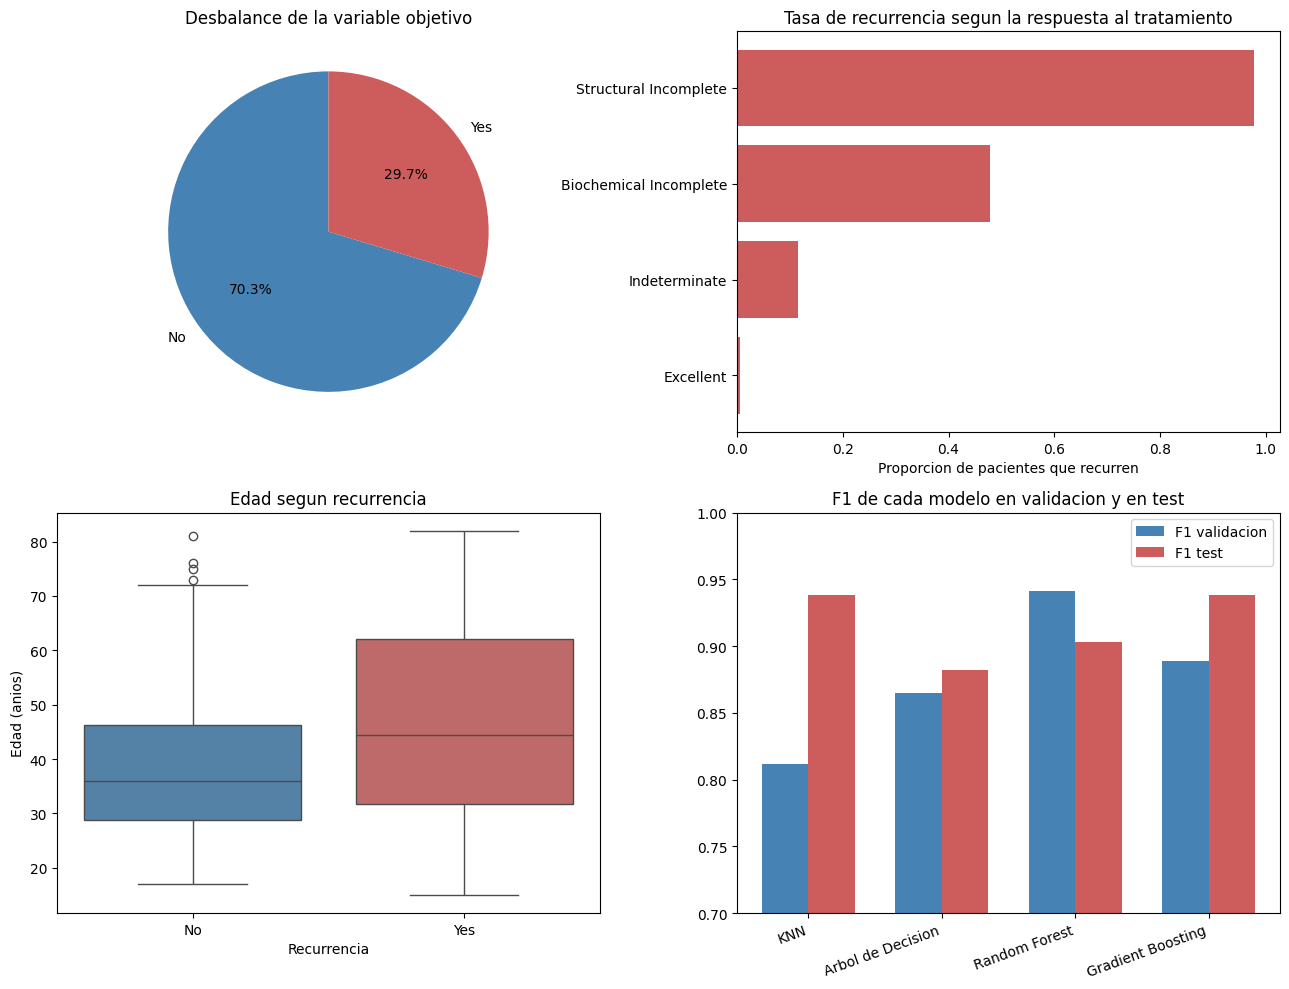

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (1,1) Distribucion de la variable objetivo
conteo = df['Recurred'].value_counts()
axes[0, 0].pie(conteo, labels=conteo.index, autopct='%1.1f%%',
               colors=['steelblue', 'indianred'], startangle=90)
axes[0, 0].set_title('Desbalance de la variable objetivo')

# (1,2) Tasa de recurrencia por respuesta al tratamiento
tasa_resp = pd.crosstab(df['Response'], df['Recurred'], normalize='index')['Yes']
tasa_resp = tasa_resp.sort_values()
axes[0, 1].barh(tasa_resp.index, tasa_resp.values, color='indianred')
axes[0, 1].set_title('Tasa de recurrencia segun la respuesta al tratamiento')
axes[0, 1].set_xlabel('Proporcion de pacientes que recurren')

# (2,1) Edad segun recurrencia
sns.boxplot(data=df, x='Recurred', y='Age', hue='Recurred',
            palette=['steelblue', 'indianred'], legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Edad segun recurrencia')
axes[1, 0].set_xlabel('Recurrencia')
axes[1, 0].set_ylabel('Edad (anios)')

# (2,2) Desempeno de los modelos
x = np.arange(len(tabla_val.index))
ancho = 0.35
axes[1, 1].bar(x - ancho / 2, tabla_val['F1 (val)'], ancho, label='F1 validacion', color='steelblue')
axes[1, 1].bar(x + ancho / 2, tabla_test['F1'], ancho, label='F1 test', color='indianred')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(tabla_val.index, rotation=20, ha='right')
axes[1, 1].set_ylim(0.7, 1.0)
axes[1, 1].set_title('F1 de cada modelo en validacion y en test')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Conclusiones**

El problema de clasificación de recurrencia de cáncer diferenciado de tiroides resultó ser un problema "fácil" en términos de desempeño y difícil en términos de tamaño muestral. Los cuatro modelos superaron ampliamente la línea base del 70.3% que daría predecir siempre "no recurre", y el modelo seleccionado, **Random Forest**, alcanzó un F1 de 0.941 en validación, 0.903 en test y 0.926 ± 0.017 en validación cruzada. La razón de fondo es la que muestran las gráficas del subplot: variables como `Response` y `Risk` separan las clases casi por completo —entre los pacientes con respuesta estructural incompleta recurre el 97.8%, y entre los de riesgo bajo apenas el 5.2%—, así que cualquier modelo capaz de partir por esas variables llega lejos.

**Por qué ganó Random Forest, relacionándolo con las características de cada algoritmo.** El dataset es casi enteramente categórico y las fronteras entre clases son escalonadas ("si el riesgo es alto, recurre"), no lineales ni suaves. Ese es el terreno natural de los modelos basados en árboles, que particionan el espacio por umbrales y manejan variables categóricas codificadas sin problema. El **árbol individual** capta bien esas reglas pero tiene varianza alta: sin poda memorizó el entrenamiento (métricas de 1.000) y cayó a 0.865 de F1 en validación. **Random Forest** ataca exactamente esa debilidad: al promediar muchos árboles entrenados sobre muestras bootstrap y con subconjuntos aleatorios de variables reduce la varianza sin aumentar el sesgo, y por eso su brecha train→validación fue la más pequeña. **Gradient Boosting**, que reduce sesgo secuencialmente en lugar de reducir varianza por promediado, quedó muy cerca pero con más falsos positivos, lo esperable en un modelo que necesita ajuste de `learning_rate` para rendir al máximo. **KNN** fue el más débil en validación (recall 0.765), y la explicación también es estructural: es el único modelo sensible a la escala —de ahí que el escalamiento fuera obligatorio— y el único que sufre con las 41 dimensiones resultantes del encoding, de las cuales 36 son binarias. En un espacio así, las distancias euclidianas entre pacientes pierden capacidad de discriminación, y con 254 filas de entrenamiento los cinco vecinos más cercanos no son necesariamente parecidos.

**Qué limpieza fue más determinante.** El dataset venía sin nulos y sin inconsistencias de formato, así que la limpieza propiamente dicha se redujo a eliminar 19 filas duplicadas. Lo verdaderamente determinante no fue la limpieza sino las **decisiones de transformación**: codificar `Risk`, `T`, `N` y `Stage` como ordinales en lugar de One-Hot mantuvo el orden clínico del estadiaje TNM y bajó la matriz de entrada de 55 a 41 columnas, lo que beneficia directamente a KNN; y escalar las variables numéricas y ordinales fue indispensable para que KNN pudiera competir. La decisión de estratificar las tres particiones también fue clave: con 55 filas por conjunto y una clase positiva del 29.7%, sin estratificar las métricas habrían sido erráticas.

**Comparación estructural con el problema de regresión.** Los dos problemas del workshop comparten el mismo esqueleto metodológico —limpieza justificada, pipeline con `ColumnTransformer` ajustado solo en train, comparación de modelos en validación, reporte en test— pero se separan en dos puntos. El primero es la naturaleza del target: aquí es una etiqueta binaria, lo que obliga a usar accuracy, precisión, recall, F1 y matriz de confusión, y a razonar sobre el costo asimétrico de los errores; en regresión el target es continuo y se evalúa con MAE, MSE y R², donde no existe la noción de "falso negativo" y el error se mide en las unidades del problema. Por eso la Regresión Lineal Múltiple aparece en el notebook de regresión y no en este: predice cualquier número real, mientras que `Recurred` solo admite dos valores. El segundo punto es la composición de las variables: este dataset es casi todo categórico con una sola columna continua, mientras que el de precios de vuelos combina numéricas continuas con categóricas de alta cardinalidad. Esa diferencia cambia el peso relativo de cada decisión: aquí lo crítico fue el encoding, y allá lo es además el tratamiento de outliers y el escalamiento de varias variables continuas. Lo que sí es común a ambos es la lógica de sesgo y varianza: los modelos de árbol sin restricción memorizan el entrenamiento en los dos casos, y los ensambles corrigen ese problema por caminos distintos (bagging reduce varianza, boosting reduce sesgo).

**Limitaciones del estudio.**

1. **Tamaño de la muestra.** 364 pacientes, con 55 en validación y 55 en test, es poco. Como se vio en el punto 23, el ranking de los modelos cambió entre validación y test por diferencias de uno o dos pacientes; los cuatro modelos son, con estos datos, estadísticamente indistinguibles entre sí.
2. **La variable `Response` es posterior al tratamiento.** Describe la respuesta a la terapia inicial, y una respuesta "estructural incompleta" significa que ya se detectó enfermedad residual. Incluirla hace que el modelo prediga muy bien, pero limita su utilidad como herramienta de pronóstico temprano: en el momento del diagnóstico esa información todavía no existe. Un modelo pensado para decidir el seguimiento desde el diagnóstico debería entrenarse sin ella.
3. **Duplicados ambiguos.** Al no haber identificador de paciente, no se puede saber si las 19 filas eliminadas eran errores de captura o pacientes distintos con el mismo perfil clínico.
4. **Sin ajuste de hiperparámetros.** Los modelos se entrenaron con los valores por defecto. Podar el árbol o ajustar `k` en KNN y el `learning_rate` de Gradient Boosting cambiaría las comparaciones.
5. **Cohorte única.** Los datos provienen de un solo centro y de una población específica; el desempeño podría no trasladarse a otra población con distinta distribución de estadios o de tipos histológicos.

**Preguntas abiertas.** ¿Cuánto desempeño se pierde al entrenar solo con variables disponibles al momento del diagnóstico, excluyendo `Response`? ¿Se mantiene la ventaja de Random Forest si se ajustan hiperparámetros por validación cruzada, o Gradient Boosting la supera? Dado que el falso negativo es el error costoso, ¿convendría mover el umbral de decisión por debajo de 0.5 para ganar recall a costa de más falsos positivos, y qué umbral aceptaría el equipo clínico? Y por último, ¿qué variables pesan realmente en la predicción según la importancia de características del bosque, y coinciden con los factores pronósticos que la literatura clínica ya reconoce?